# My objective with this notebook:

- Learn how to open geodataframe
- How to do descriptive statics and plotting
- Query the dataset and custom plotting

# Geographic Tables

In [2]:
#| include: false
import warnings, osmnx

warnings.filterwarnings("ignore")
osmnx.settings.overpass_settings = '[out:json][timeout:90][date:"2021-10-07T00:00:00Z"]'

In [4]:
import pandas
import osmnx
import geopandas as gpd
import rioxarray
import xarray
import datashader
import contextily as cx
from shapely import geometry
import matplotlib.pyplot as plt

In [71]:
gt_polygons = gpd.read_file("../data/countries/countries_clean.gpkg")

In [76]:
gt_polygons

,ADMIN,geometry
0,Indonesia,"MULTIPOLYGON (((13102705.696 463877.598, 13102..."
1,Malaysia,"MULTIPOLYGON (((13102705.696 463877.598, 13101..."
2,Chile,"MULTIPOLYGON (((-7737827.685 -1979875.5, -7737..."
3,Bolivia,"POLYGON ((-7737827.685 -1979875.5, -7737828.21..."
4,Peru,"MULTIPOLYGON (((-7737827.685 -1979875.5, -7752..."
...,...,...
155,Taiwan,"MULTIPOLYGON (((13570488.501 2869616.777, 1356..."
156,Japan,"MULTIPOLYGON (((14447401.267 3737037.331, 1444..."
157,Iceland,"MULTIPOLYGON (((-1621215.732 9982883.495, -162..."
158,Solomon Islands,"MULTIPOLYGON (((17867187.118 -1315679.987, 178..."


In [72]:
# let's inspect the structural summaries 
# (columns, data types, non-null, and memory usage)
gt_polygons.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   ADMIN     160 non-null    str     
 1   geometry  160 non-null    geometry
dtypes: geometry(1), str(1)
memory usage: 2.6 KB


In [73]:
# ?? gt_polygons.describe

In [75]:
type(gt_polygons)

geopandas.geodataframe.GeoDataFrame

In [28]:
# Generate descriptive statistc

gt_polygons.describe(include="all")

,ADMIN,geometry
count,160,160
unique,160,160
top,Indonesia,MULTIPOLYGON (((13102705.696399428 463877.5978...
freq,1,1


In [15]:
# let's check the data

gt_polygons.head()

,ADMIN,geometry
0,Indonesia,"MULTIPOLYGON (((13102705.696 463877.598, 13102..."
1,Malaysia,"MULTIPOLYGON (((13102705.696 463877.598, 13101..."
2,Chile,"MULTIPOLYGON (((-7737827.685 -1979875.5, -7737..."
3,Bolivia,"POLYGON ((-7737827.685 -1979875.5, -7737828.21..."
4,Peru,"MULTIPOLYGON (((-7737827.685 -1979875.5, -7752..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

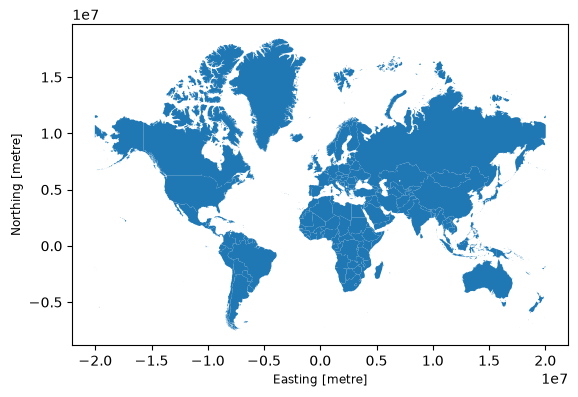

In [35]:
gt_polygons.plot()

## Add centroid

In [36]:
gt_polygons["centroid"] = gt_polygons.geometry.centroid

In [40]:
# let's check the data

gt_polygons.head()

,ADMIN,geometry,centroid
0,Indonesia,"MULTIPOLYGON (((13102705.696 463877.598, 13102...",POINT (13055431.81 -248921.141)
1,Malaysia,"MULTIPOLYGON (((13102705.696 463877.598, 13101...",POINT (12211696.493 422897.505)
2,Chile,"MULTIPOLYGON (((-7737827.685 -1979875.5, -7737...",POINT (-7959811.948 -4915458.802)
3,Bolivia,"POLYGON ((-7737827.685 -1979875.5, -7737828.21...",POINT (-7200010.945 -1894653.148)
4,Peru,"MULTIPOLYGON (((-7737827.685 -1979875.5, -7752...",POINT (-8277554.831 -1032942.536)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

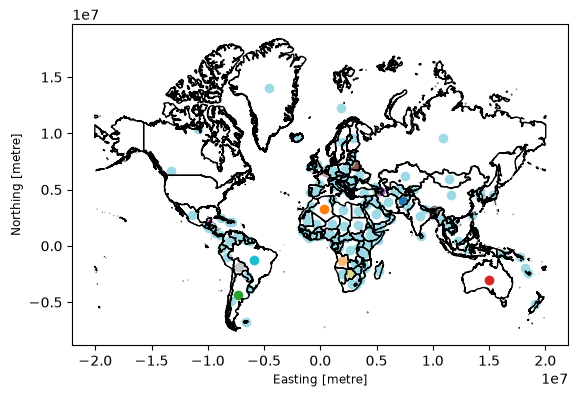

In [48]:
# instead of plotting using the geometry, I want to use the centroid
# Why a lot of blue polygons eventough we have 160 unique data? 

ax = gt_polygons.set_geometry("centroid").plot("ADMIN") # bottom layer
gt_polygons.plot(ax=ax, facecolor="none") # top layer

## Data query

In [59]:
# I want to get indonesia
# Let's check what is the unique, use query()

malay_polygons = gt_polygons.query('ADMIN == "Indonesia" or ADMIN == "Malaysia"')

In [61]:
malay_polygons

,ADMIN,geometry,centroid
0,Indonesia,"MULTIPOLYGON (((13102705.696 463877.598, 13102...",POINT (13055431.81 -248921.141)
1,Malaysia,"MULTIPOLYGON (((13102705.696 463877.598, 13101...",POINT (12211696.493 422897.505)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

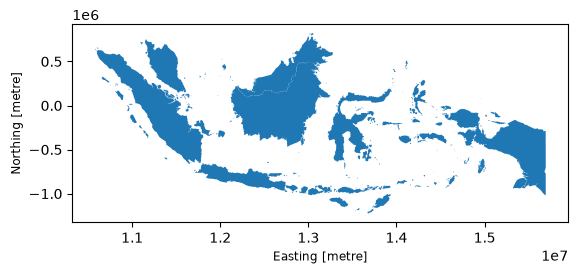

In [60]:
malay_polygons.plot()

### How to explode into single polygons?

In [65]:
# why we need to use index_parts = False? avoid parent-child lineage
malay_exploded = malay_polygons.explode(index_parts=False).reset_index(drop=True)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

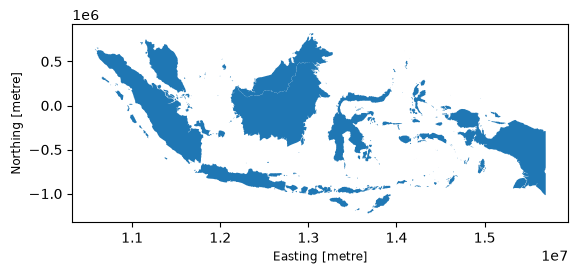

In [63]:
malay_exploded.plot()

### How to color based on areas?

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

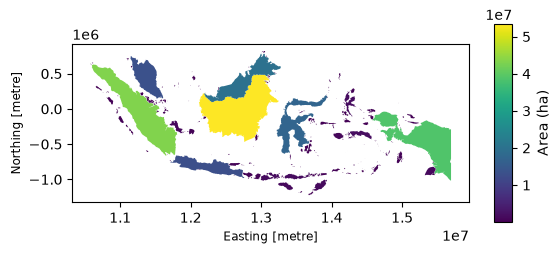

In [69]:
# calculate area first
# convert m2 to ha
# 1 ha = 10000 m2
malay_exploded["area"] = malay_exploded.geometry.area / 1e4

# plot colored by area
# bright yellow = larges, dark purple = smallest

malay_exploded.plot("area", cmap="viridis", legend=True, 
                   legend_kwds={"label": "Area (ha)"})

# what does each polygons represent? it's an island